# Theory

## Tokenization

### What is Tokenization?

**Tokenization** is the process of breaking down a stream of text into smaller units called **tokens**. These tokens can be words, subwords, characters, or even symbols. Tokenization is one of the foundational steps in Natural Language Processing (NLP) because it transforms raw text into a structured format that models can understand and process.

### Why is Tokenization Necessary?

Human language is complex, ambiguous, and often unstructured. For machines to work with text, it must be converted into a numeric form. Tokenization is essential because machine learning models cannot directly process text. Tokenization provides a way to represent text in numerical form. These numerical representations are what the models can process and learn from.

### How Tokenization Works

The method of tokenization depends on the type of model and the task at hand. Here's an overview of common approaches:

1. Word-Level Tokenization

* Each word becomes a token.
* Large vocabulary, sensitive to spelling variations and OOV (out-of-vocabulary) words.

2. Subword Tokenization

* Splits words into smaller, more frequent units (subwords).
* Balances between vocabulary size and coverage.
* Common subword algorithms:
    * Byte-Pair Encoding (BPE)
    * WordPiece
    * Unigram Language Model
* Generally these tokenizers also have special tokens that have distinct use-cases (e.g., [CLS], [PAD])

3. Character-Level Tokenization

* Each character is a token.
* Small vocabulary, but long sequences.

### Examples of Tokenizers in NLP Models

#### Traditional Word Embedding Models

| Model        | Tokenization Method | Notes                                     |
| ------------ | ------------------- | ----------------------------------------- |
| **GloVe**    | Word-level          | Fixed vocabulary; OOV words are an issue. |
| **Word2Vec** | Word-level          | No subword handling; large vocab needed.  |

These models treat each word as a distinct token. Once trained, they assign a dense vector to each token in the vocabulary.

#### Modern Transformer-Based Models

| Model           | Tokenization Method        | Notes                                                                       |
| --------------- | -------------------------- | --------------------------------------------------------------------------- |
| **BERT**        | WordPiece                  | Splits rare words into subwords; e.g., “playing” → “play”, “##ing”.         |
| **GPT (2/3/4)** | BPE                        | Efficient subword tokenization; balances vocab size with language coverage. |
| **T5**          | SentencePiece (Unigram LM) | Fully unsupervised; language-independent approach.                          |
| **LLaMA**       | SentencePiece (BPE)        | Uses BPE; optimized for open-domain tasks in low-resource settings.         |

These models use subword tokenization to handle rare or unknown words while maintaining efficient and expressive representations.

## Padding

### Why is it necessary?

Padding ensures that all input sequences in a batch are of uniform length. This is important because:
1. Models usually process multiple sequences at once (in batches), and most neural networks expect each input in a batch to have the same length.
2. Fixed-length inputs allow for parallel computation, making the training and inference processes more efficient.

### How it Works?

In text data, sequences can have varying lengths (e.g., one sentence might have 10 tokens, while another might have 15).

Padding adds tokens (e.g., a special token like [PAD]) to the shorter sequences until they reach the length of the longest sequence in the batch (or a predefined maximum length).

### Types of Padding

Pre-padding: Padding tokens are added to the beginning of the sequence. This is usually used for decoder-based models.

Post-padding: Padding tokens are added to the end of the sequence. This is generally used for encoder seq2seq models.

### Impact on training models

Padding tokens usually do not carry any useful information for the model, so special attention is needed to ensure that these tokens don't influence the learning process. This is often handled by masking out the padded tokens (e.g., setting their corresponding labels to -100) in models, so they don't contribute to loss calculations during training.

## Training Guide

### Choosing the Right Model

* **Pretrained Models**: Start with a pretrained transformer model. They often perform well on a wide range of tasks. If you have limited resources, use smaller variants for faster training and inference.

* **Task-Specific Models**: Some models are better suited for specific tasks. For example:

  * Encoder models are excellent for tasks like classification, named entity recognition, or information retrieval.
  * Encoder-Decoder (Sequence-to-Sequence) models are great for tasks like text summarization and machine translation.
  * Decoder models are suited for generative tasks like text generation and completion.
  
* **Fine-tuning vs. Training From Scratch**: Fine-tuning a pretrained transformer model is typically faster and more effective than training from scratch, especially with smaller datasets.

### Fine-tuning Best Practices

* **Learning Rate**: When fine-tuning a transformer model, use a smaller learning rate (e.g., 2e-5 to 5e-5). Transformer models are sensitive to the learning rate, and larger values can cause catastrophic forgetting of the pretrained weights.
* **Optimizer**: Use the AdamW optimizer, which includes weight decay to regularize the model and helps prevent overfitting. It is commonly used for transformer-based models.
* **Warmup Steps**: Implement learning rate warm-up for the first part of training (e.g., 5% of total training steps). This helps stabilize training when fine-tuning large models.
* **Batch Size**: A batch size of 16, 32 or 64 is common for transformer-based models. Due to memory constraints, batch sizes may need to be smaller for larger models. Ensure that your batch size fits within your GPU memory limits.
* **Gradient Accumulation**: If you cannot fit a large batch size into memory, use gradient accumulation. This technique simulates a larger batch size by accumulating gradients over multiple smaller batches before updating the model's weights.
* **Early Stopping**: Monitor validation loss or another relevant metric during training and stop early if the model's performance plateaus or starts to degrade.

### Handling Long Sequences

* **Sequence Length**: Transformer models, have a maximum sequence length (e.g., 512 tokens for BERT). Ensure that you don't exceed this length when processing long documents.
* **Truncation and Padding**: If your sequences exceed the model's maximum length, truncate them. If they are too short, pad them. Be careful with truncation as you might lose important information. You can try splitting long documents into smaller chunks.
* **Sliding Window**: For tasks like document classification, you can use a sliding window approach to process longer texts. This involves dividing the text into overlapping windows and aggregating results.

### Handling Imbalanced Data

* **Class Weights**: For classification tasks with imbalanced classes, consider adjusting class weights during training. This will help the model pay more attention to the minority classes.
* **Sampling Techniques**: Use oversampling or undersampling techniques to balance the dataset. Alternatively, use data augmentation methods to synthetically generate additional examples for the minority class.

### Evaluation and Hyperparameter Tuning

* **Evaluation Strategy**: Regularly evaluate the model on a validation set during training. Make sure you're not overfitting to the training data, and you can also track performance metrics like F1-score, precision, and recall, depending on the task.
* **Hyperparameter Tuning**: Tune hyperparameters like the learning rate, batch size, and weight decay. These can be done through methods like grid search or random search, or Bayesian optimization for more efficient hyperparameter exploration. Two packages you might be interested in for hyperparameter tuning are Optuna and Ray-Tune.

###Dealing with Overfitting

* **Dropout**: Use dropout in the transformer model to prevent overfitting, especially for larger models.
* **Regularization**: Apply weight decay (as part of the AdamW optimizer) to avoid overfitting by penalizing overly large weights.
* **Data Augmentation**: For tasks like text classification, augment the data using techniques like backtranslation, or easy data agumentation(EDA).

# Initial Configurations

# Imports and Dataset Loading

In [1]:
!pip install -q datasets transformers accelerate scikit-learn

In [2]:
import os
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence
from torch.optim import AdamW
from transformers import (
    AutoModelForCausalLM,
    AutoModel,
    AutoModelForMaskedLM,
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    DataCollatorWithPadding,
)
# from trl import DataCollatorForCompletionOnlyLM
from datasets import load_dataset, Dataset
from sklearn.metrics import f1_score, accuracy_score
from tqdm import tqdm

from datasets import DatasetDict, ClassLabel

# 20 Newsgroups (headers, footers and quotes already stripped). Only train/test splits exist.
raw = load_dataset("SetFit/20_newsgroups")

# Some posts are empty after stripping headers/quotes -> drop them
raw = raw.filter(lambda ex: len(ex["text"].strip()) > 0)

# Carve a stratified validation split out of the training set
# Cast to ClassLabel (keeps the original 0-19 ids) so we can stratify
raw["train"] = raw["train"].cast_column("label", ClassLabel(num_classes=20))
split = raw["train"].train_test_split(test_size=0.1, seed=42, stratify_by_column="label")
dataset = DatasetDict({
    "train": split["train"],
    "validation": split["test"],
    "test": raw["test"],
})

README.md:   0%|          | 0.00/734 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B / 14.8MB            

train.jsonl: downloading bytes:           |  0.00B            

test.jsonl: reconstructing file:   0%|          |  0.00B / 8.91MB            

test.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11314 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7532 [00:00<?, ? examples/s]

Filter:   0%|          | 0/11314 [00:00<?, ? examples/s]

Filter:   0%|          | 0/7532 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/11014 [00:00<?, ? examples/s]

In [3]:
# Build the id -> name mapping from the dataset itself (20 classes)
label_map = dict(sorted({ex["label"]: ex["label_text"] for ex in raw["test"]}.items()))
NUM_LABELS = len(label_map)
print(NUM_LABELS, label_map)

20 {0: 'alt.atheism', 1: 'comp.graphics', 2: 'comp.os.ms-windows.misc', 3: 'comp.sys.ibm.pc.hardware', 4: 'comp.sys.mac.hardware', 5: 'comp.windows.x', 6: 'misc.forsale', 7: 'rec.autos', 8: 'rec.motorcycles', 9: 'rec.sport.baseball', 10: 'rec.sport.hockey', 11: 'sci.crypt', 12: 'sci.electronics', 13: 'sci.med', 14: 'sci.space', 15: 'soc.religion.christian', 16: 'talk.politics.guns', 17: 'talk.politics.mideast', 18: 'talk.politics.misc', 19: 'talk.religion.misc'}


In [4]:
print(f"Train Size: {len(dataset["train"])}")
print(f"Val Size: {len(dataset["validation"])}")
print(f"Test Size: {len(dataset["test"])}")
print(dataset["train"][0])


Train Size: 9912
Val Size: 1102
Test Size: 7317
{'text': "\n\tBeing a proud BU alumnus, I'd like to get a list of BU players in \nthe NHL so I can keep an eye on their progress. A lot of Terriers are\ngraduating this year so I hope to see them soon in the NHL. If somebody\ncould post or send me a list, I'd appreciate it. Please note if the player\ngraduated from here or not.\n", 'label': 10, 'label_text': 'rec.sport.hockey'}


# Encoder Training

At a high level an encoder's model primary function is to transform input data often sequential (e.g., text, audio, time series), into a fixed-size or variable-length vector representation that captures contextual information from the input.

The encoder's input and output:

* Input: "The solar system has 8 planets."
* Tokens: \[tok1, tok2, ..., tok\_n]
* Output: \[h1, h2, ..., h\_n] (contextual vectors for each token)

Each output vector `h_i` represents the meaning of token `tok_i` in the context of the full sequence, using attention mechanisms (in Transformer-based models).

Encoders, especially in NLP, are pre-trained using the **Masked Language Modeling** task where random tokens are masked and the model is trained to predict them:

  * Input: "The \[MASK] system has 8 planets."
  * Labels: \[-100, target\_token, -100, ...]
  * Loss is computed only at masked positions.

Additionally, one can also apply **task-specific fine-tuning**, for tasks like classification, of which we will next see a few examples.

## Version 1 - Encoder Backbone with Multiple Classification Heads

### Constants and Models Initialization

In [5]:
import torch

print("GPU disponibil:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU disponibil: True
GPU: Tesla T4


In [6]:
MODEL_NAME = "answerdotai/ModernBERT-base"
SAVED_MODEL_NAME = "saved_encoder_model_v1"
NUM_EPOCHS = 5
BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 2
LEARNING_RATE = 5e-5
MAX_LENGTH = 512  # newsgroup posts are long; ModernBERT supports up to 8192 if memory allows

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

In [8]:
class BertClassifier(torch.nn.Module):
    def __init__(self, num_labels=NUM_LABELS):
        super().__init__()
        self.bert = AutoModel.from_pretrained(MODEL_NAME).to(device)
        hidden_size = self.bert.config.hidden_size

        self.classification_head = torch.nn.Linear(hidden_size, num_labels)  # 20-class

    def forward(self, input_ids, attention_mask=None, token_type_ids=None):
        # Get BERT output
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        # Use the [CLS] pooled output
        # pooled_output = outputs.pooler_output  # shape: [batch_size, hidden_size]

        """
        # For averaging the embeddings instead of just using the pooled output
        mask = attention_mask.unsqueeze(-1).type(torch.float32)
        masked_hidden_state = outputs.last_hidden_state * mask
        sum_hidden = masked_hidden_state.sum(dim=1)
        lengths = mask.sum(dim=1).clamp(min=1e-9)  # prevent division by zero
        mean_pooled = sum_hidden / lengths
        """
        mask = attention_mask.unsqueeze(-1).type(torch.float32)
        masked_hidden_state = outputs.last_hidden_state * mask
        sum_hidden = masked_hidden_state.sum(dim=1)
        lengths = mask.sum(dim=1).clamp(min=1e-9)  # prevent division by zero
        mean_pooled = sum_hidden / lengths


        # Pass through both heads
        logits = self.classification_head(mean_pooled)

        return logits

model = BertClassifier().to(device)
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [9]:
print("Device:", device)
print("Hidden size:", model.bert.config.hidden_size)
print("Număr clase:", model.classification_head.out_features)

Device: cuda
Hidden size: 768
Număr clase: 20


### Tokenization and Dataset Preparation

In [10]:
def tokenize_function(example):
    # Tokenize the input prompt
    inputs = tokenizer(
        example['text'],
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    inputs["label"] = example["label"]

    # Squeeze the tensors to (seq_len), since the tokenizer puts outputs the shape (1, seq_len)
    inputs["input_ids"] = inputs["input_ids"].squeeze()
    # inputs["token_type_ids"] = inputs["token_type_ids"].squeeze()
    inputs["attention_mask"] = inputs["attention_mask"].squeeze()

    return inputs

In [11]:
def collate_fn(batch, tokenizer):
    input_ids = pad_sequence([torch.tensor(example['input_ids']) for example in batch], batch_first=True, padding_value=tokenizer.pad_token_id)
    attention_mask = pad_sequence([torch.tensor(example['attention_mask']) for example in batch], batch_first=True, padding_value=0)

    label = torch.stack([torch.tensor(item['label']) for item in batch])

    return {
        'input_ids': input_ids,               # [batch_size, seq_len]
        'attention_mask': attention_mask,     # [batch_size, seq_len]
        'label': label,                     # [batch_size]
    }

my_collate_fn = lambda batch: collate_fn(batch, tokenizer)

In [12]:
train_dataset = dataset["train"].map(tokenize_function, batched=False, remove_columns=["text", "label_text"])
val_dataset = dataset["validation"].map(tokenize_function, batched=False, remove_columns=["text", "label_text"])

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=my_collate_fn, # Data collator that pads the input and labels to the same size
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=my_collate_fn, # Data collator that pads the input and labels to the same size
)


Map:   0%|          | 0/9912 [00:00<?, ? examples/s]

Map:   0%|          | 0/1102 [00:00<?, ? examples/s]

In [14]:
batch = next(iter(train_loader))

print("Input IDs:", batch["input_ids"].shape)
print("Attention mask:", batch["attention_mask"].shape)
print("Labels:", batch["label"].shape)

Input IDs: torch.Size([8, 512])
Attention mask: torch.Size([8, 512])
Labels: torch.Size([8])


### Training Loop

In [13]:
# Return the mean loss over the validation set
def validate(model, dataloader, device):
    model.eval()
    running = 0.0
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            logits = model(input_ids=input_ids, attention_mask=attention_mask) # Run the batch through the model

            # Compute the two losses
            loss = loss_fn(logits, labels)

            running += loss.item()
    model.train()
    return running / len(dataloader)

In [15]:
val_interval = len(train_loader) // 10 # The interval in which we evaluate on the validation set (10%)
loss_fn = torch.nn.CrossEntropyLoss()
best_val_loss = float("inf")
early_stopping = 0

for epoch in range(NUM_EPOCHS):
    running_train_loss = 0.0 # Accumulated loss per this epoch
    steps_in_epoch = 0 # To calculate the mean loss per epoch
    step_loss = 0.0  # Accumulates micro‑batch losses
    optimizer.zero_grad()
    force_break = False

    for micro_step, batch in tqdm(enumerate(train_loader), total=len(train_loader)):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)

        logits = model(input_ids=input_ids, attention_mask=attention_mask) # Run the batch through the model

        # Compute the two losses
        loss = loss_fn(logits, labels)


        loss = loss / GRADIENT_ACCUMULATION_STEPS  # Scale loss for gradient accumulation

        loss.backward()
        step_loss += loss.item()

        # If we reached the gradient accumulation steps, do back-propagation
        if (micro_step + 1) % GRADIENT_ACCUMULATION_STEPS == 0 or (micro_step + 1) == len(train_loader):
            optimizer.step()
            optimizer.zero_grad()

            # Mean loss for this optimiser step
            mean_step_loss = step_loss
            steps_in_epoch += 1
            running_train_loss += mean_step_loss

            # print(f"Train Batch Mean Loss: {mean_step_loss:.4f}")

            # Periodic validation
            if (micro_step + 1) % val_interval == 0 or (micro_step + 1) == len(train_loader):
                val_loss = validate(model, val_loader, device)
                print(f"Validation Loss: {val_loss:.4f}")
                if val_loss < best_val_loss:
                    print("Saving best checkpoint")
                    best_val_loss = val_loss
                    if not os.path.exists(f"./checkpoints/{SAVED_MODEL_NAME}"):
                        os.makedirs(f"./checkpoints/{SAVED_MODEL_NAME}")
                    torch.save(model, f"./checkpoints/{SAVED_MODEL_NAME}/model.pt")
                    tokenizer.save_pretrained(f"./checkpoints/{SAVED_MODEL_NAME}")
                    early_stopping = 0
                else:
                    print("Validation loss didn't improve")
                    early_stopping += 1
                    if early_stopping == 3:
                        print("Validation loss didn't improve for too long")
                        force_break = True
                        break


            step_loss = 0.0 # Reset micro-step loss accumulator

    if force_break:
        break

    avg_epoch_loss = running_train_loss / steps_in_epoch
    print(f"Epoch {epoch + 1} complete | Avg Train Loss: {avg_epoch_loss:.4f}")



print("Training finished.")

 20%|█▉        | 245/1239 [03:57<14:54,  1.11it/s]

Validation Loss: 1.1767
Saving best checkpoint


 40%|███▉      | 491/1239 [08:46<09:48,  1.27it/s]

Validation Loss: 1.0016
Saving best checkpoint


 59%|█████▉    | 737/1239 [13:41<08:37,  1.03s/it]

Validation Loss: 0.9565
Saving best checkpoint


... (6 outputs left out)

 20%|█▉        | 246/1239 [04:40<3:46:28, 13.68s/it]

Validation Loss: 0.9809
Validation loss didn't improve


 40%|███▉      | 491/1239 [09:17<14:09,  1.14s/it]

Validation Loss: 0.8784
Validation loss didn't improve
Validation loss didn't improve for too long
Training finished.


### Evaluation

In [16]:
tokenizer = AutoTokenizer.from_pretrained(f"./checkpoints/{SAVED_MODEL_NAME}")
model = torch.load(f"./checkpoints/{SAVED_MODEL_NAME}/model.pt", weights_only=False)
model.to(device)

BertClassifier(
  (bert): ModernBertModel(
    (embeddings): ModernBertEmbeddings(
      (tok_embeddings): Embedding(50368, 768, padding_idx=50283)
      (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
      (drop): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0): ModernBertEncoderLayer(
        (attn_norm): Identity()
        (attn): ModernBertAttention(
          (Wqkv): Linear(in_features=768, out_features=2304, bias=False)
          (Wo): Linear(in_features=768, out_features=768, bias=False)
          (out_drop): Identity()
        )
        (mlp_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
        (mlp): ModernBertMLP(
          (Wi): Linear(in_features=768, out_features=2304, bias=False)
          (act): GELUActivation()
          (drop): Dropout(p=0.0, inplace=False)
          (Wo): Linear(in_features=1152, out_features=768, bias=False)
        )
      )
      (1-21): 21 x ModernBertEncoderLayer(
     

In [17]:
model.eval()
test_dataset = dataset["test"].map(tokenize_function, batched=False, remove_columns=["text", "label_text"])

targets = []
predictions = []
for data in tqdm(test_dataset):
    target = data["label"]
    del data["label"]
    for key, tensor in data.items():
        data[key] = torch.tensor(tensor).unsqueeze(0).to(device)

    # Run the input through the model, generate the output and decode the tokens
    with torch.no_grad():
        logits = model(**data)
        prediction = torch.argmax(logits, dim=1).item()
    targets.append(target)
    predictions.append(prediction)

Map:   0%|          | 0/7317 [00:00<?, ? examples/s]

100%|██████████| 7317/7317 [03:06<00:00, 39.31it/s]


In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print(f"Precision: {precision_score(targets, predictions, average='macro')}")
print(f"Recall: {recall_score(targets, predictions, average='macro')}")
print(f"F1: {f1_score(targets, predictions, average='macro')}")
print(f"Accuracy: {accuracy_score(targets, predictions)}")

from sklearn.metrics import classification_report
print(classification_report(targets, predictions, target_names=[label_map[i] for i in range(NUM_LABELS)], zero_division=0))

Precision: 0.7089263221701902
Recall: 0.6912977333682114
F1: 0.6843686000728899
Accuracy: 0.7065737324039907
                          precision    recall  f1-score   support

             alt.atheism       0.38      0.63      0.48       311
           comp.graphics       0.67      0.69      0.68       384
 comp.os.ms-windows.misc       0.61      0.75      0.68       379
comp.sys.ibm.pc.hardware       0.73      0.51      0.60       386
   comp.sys.mac.hardware       0.61      0.79      0.69       371
          comp.windows.x       0.79      0.81      0.80       391
            misc.forsale       0.84      0.79      0.82       382
               rec.autos       0.78      0.77      0.77       375
         rec.motorcycles       0.67      0.72      0.69       386
      rec.sport.baseball       0.93      0.79      0.85       383
        rec.sport.hockey       0.85      0.93      0.89       390
               sci.crypt       0.84      0.70      0.77       380
         sci.electronics       0

## Version 2 - Using only pre-trained knowledge by predicting mask tokens
Instead of adding a classification head, use the already trained MLM head from Bert. You can prepare your prompt such that you only need to mask the correct label.
e.g.:
```
Classify the following newsgroup post into:
0 - alt.atheism
1 - comp.graphics
...
19 - talk.religion.misc

Post: {text}
Label: <mask>
```





In [19]:
from google.colab import drive
import shutil

drive.mount("/content/drive")

shutil.copytree(
    "./checkpoints/saved_encoder_model_v1",
    "/content/drive/MyDrive/NLP-Master/Lab02_Encoder_Finetuning/checkpoints/saved_encoder_model_v1",
    dirs_exist_ok=True
)

print("Checkpoint salvat în Google Drive!")

Mounted at /content/drive
Checkpoint salvat în Google Drive!


In [20]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "answerdotai/ModernBERT-base"
)

print("Mask token:", tokenizer.mask_token)
print("Mask token ID:", tokenizer.mask_token_id)

for i in range(20):
    tokens = tokenizer.encode(str(i), add_special_tokens=False)
    print(i, "->", tokens)

Mask token: [MASK]
Mask token ID: 50284
0 -> [17]
1 -> [18]
2 -> [19]
3 -> [20]
4 -> [21]
5 -> [22]
6 -> [23]
7 -> [24]
8 -> [25]
9 -> [26]
10 -> [740]
11 -> [883]
12 -> [805]
13 -> [1012]
14 -> [1047]
15 -> [1010]
16 -> [1036]
17 -> [1166]
18 -> [1093]
19 -> [746]


In [21]:

# Modelul ModernBERT folosește [MASK], nu <mask>

# Construim lista celor 20 de categorii
labels_description = "\n".join(
    f"{i} - {label_map[i]}"
    for i in range(NUM_LABELS)
)

def build_prompt(text):
    return (
        "Classify the following newsgroup post into:\n"
        f"{labels_description}\n\n"
        f"Post: {text}\n"
        f"Label: {tokenizer.mask_token}"
    )

# Testăm promptul pe primul articol
prompt = build_prompt(dataset["test"][0]["text"])

print(prompt[:1500])


Classify the following newsgroup post into:
0 - alt.atheism
1 - comp.graphics
2 - comp.os.ms-windows.misc
3 - comp.sys.ibm.pc.hardware
4 - comp.sys.mac.hardware
5 - comp.windows.x
6 - misc.forsale
7 - rec.autos
8 - rec.motorcycles
9 - rec.sport.baseball
10 - rec.sport.hockey
11 - sci.crypt
12 - sci.electronics
13 - sci.med
14 - sci.space
15 - soc.religion.christian
16 - talk.politics.guns
17 - talk.politics.mideast
18 - talk.politics.misc
19 - talk.religion.misc

Post: I am a little confused on all of the models of the 88-89 bonnevilles.
I have heard of the LE SE LSE SSE SSEI. Could someone tell me the
differences are far as features or performance. I am also curious to
know what the book value is for prefereably the 89 model. And how much
less than book value can you usually get them for. In other words how
much are they in demand this time of year. I have heard that the mid-spring
early summer is the best time to buy.
Label: [MASK]


In [22]:
encoded = tokenizer(
    prompt,
    truncation=True,
    max_length=512,
    return_tensors="pt"
)

mask_positions = (
    encoded["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0]

print("Număr tokenuri:", encoded["input_ids"].shape[1])
print("Poziții MASK:", mask_positions.tolist())

Număr tokenuri: 310
Poziții MASK: [308]


In [23]:
from transformers import AutoModelForMaskedLM

mlm_model = AutoModelForMaskedLM.from_pretrained(
    "answerdotai/ModernBERT-base"
).to(device)

mlm_model.eval()

Loading weights:   0%|          | 0/137 [00:00<?, ?it/s]

ModernBertForMaskedLM(
  (model): ModernBertModel(
    (embeddings): ModernBertEmbeddings(
      (tok_embeddings): Embedding(50368, 768, padding_idx=50283)
      (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
      (drop): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0): ModernBertEncoderLayer(
        (attn_norm): Identity()
        (attn): ModernBertAttention(
          (Wqkv): Linear(in_features=768, out_features=2304, bias=False)
          (Wo): Linear(in_features=768, out_features=768, bias=False)
          (out_drop): Identity()
        )
        (mlp_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
        (mlp): ModernBertMLP(
          (Wi): Linear(in_features=768, out_features=2304, bias=False)
          (act): GELUActivation()
          (drop): Dropout(p=0.0, inplace=False)
          (Wo): Linear(in_features=1152, out_features=768, bias=False)
        )
      )
      (1-21): 21 x ModernBertEncoderLaye

In [24]:
# ID-urile tokenurilor care reprezintă clasele 0–19
label_token_ids = [
    tokenizer.encode(str(i), add_special_tokens=False)[0]
    for i in range(NUM_LABELS)
]

# Calculăm predicția la poziția [MASK]
with torch.no_grad():
    inputs = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    outputs = mlm_model(**inputs)

    # Scorurile pentru toate tokenurile vocabularului,
    # dar numai la poziția [MASK]
    mask_logits = outputs.logits[0, mask_positions.item()]

    # Selectăm doar scorurile celor 20 de etichete
    label_scores = mask_logits[label_token_ids]

    predicted_label = torch.argmax(label_scores).item()

print("Categoria prezisă:", predicted_label, "-", label_map[predicted_label])
print("Categoria reală:", dataset["test"][0]["label_text"])

Categoria prezisă: 1 - comp.graphics
Categoria reală: rec.autos


In [26]:

import torch
import gc
from torch.utils.data import DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm
from transformers import AutoModelForMaskedLM

# Eliberăm modelul anterior din memoria GPU
if "model" in globals():
    del model
if "mlm_model" in globals():
    del mlm_model
gc.collect()
torch.cuda.empty_cache()

MODEL_NAME = "answerdotai/ModernBERT-base"
MAX_LENGTH = 512
BATCH_SIZE_MLM = 2
ACCUMULATION_STEPS = 8
NUM_EPOCHS_MLM = 5
PATIENCE = 2

# Construim promptul folosind cele 20 de categorii
labels_description = "\n".join(
    f"{i} - {label_map[i]}" for i in range(NUM_LABELS)
)

prefix = (
    "Classify the following newsgroup post into:\n"
    f"{labels_description}\n\nPost: "
)

suffix = "\nLabel: "

prefix_ids = tokenizer.encode(prefix, add_special_tokens=False)
suffix_ids = tokenizer.encode(suffix, add_special_tokens=False)

label_token_ids = [
    tokenizer.encode(str(i), add_special_tokens=False)[0]
    for i in range(NUM_LABELS)
]

def prepare_mlm(example):
    text_ids = tokenizer.encode(
        example["text"],
        add_special_tokens=False
    )

    # Rezervăm spațiu pentru prompt, MASK și tokenurile speciale
    available = MAX_LENGTH - len(prefix_ids) - len(suffix_ids) - 3
    assert available > 0

    text_ids = text_ids[:available]

    input_ids = (
        [tokenizer.cls_token_id]
        + prefix_ids
        + text_ids
        + suffix_ids
        + [tokenizer.mask_token_id]
        + [tokenizer.sep_token_id]
    )

    assert input_ids.count(tokenizer.mask_token_id) == 1

    return {
        "input_ids": input_ids,
        "target_id": label_token_ids[example["label"]]
    }

train_mlm = dataset["train"].map(prepare_mlm)
val_mlm = dataset["validation"].map(prepare_mlm)
test_mlm = dataset["test"].map(prepare_mlm)

def mlm_collate(batch):
    inputs = tokenizer.pad(
        [{"input_ids": ex["input_ids"]} for ex in batch],
        padding=True,
        return_tensors="pt"
    )
    inputs["target_id"] = torch.tensor(
        [ex["target_id"] for ex in batch],
        dtype=torch.long
    )
    return inputs

train_mlm_loader = DataLoader(
    train_mlm, batch_size=BATCH_SIZE_MLM,
    shuffle=True, collate_fn=mlm_collate
)

val_mlm_loader = DataLoader(
    val_mlm, batch_size=BATCH_SIZE_MLM,
    shuffle=False, collate_fn=mlm_collate
)

print("Train:", len(train_mlm))
print("Validation:", len(val_mlm))
print("Test:", len(test_mlm))
print("Lungime maximă:", max(len(x["input_ids"]) for x in train_mlm))


Map:   0%|          | 0/9912 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (13786 > 8192). Running this sequence through the model will result in indexing errors


Map:   0%|          | 0/1102 [00:00<?, ? examples/s]

Map:   0%|          | 0/7317 [00:00<?, ? examples/s]

Train: 9912
Validation: 1102
Test: 7317
Lungime maximă: 512


In [27]:

from pathlib import Path

device = torch.device("cuda")
mlm_model = AutoModelForMaskedLM.from_pretrained(
    MODEL_NAME
).to(device)

optimizer = AdamW(mlm_model.parameters(), lr=2e-5)
scaler = torch.amp.GradScaler("cuda")
loss_fn = torch.nn.CrossEntropyLoss()

checkpoint_dir = Path(
    "/content/drive/MyDrive/NLP-Master/"
    "Lab02_Encoder_Finetuning/checkpoints/mlm"
)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Calculăm scorurile MLM numai la poziția [MASK]
def forward_mask_logits(batch):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    hidden = mlm_model.model(
        input_ids=input_ids,
        attention_mask=attention_mask
    ).last_hidden_state

    mask_positions = input_ids == tokenizer.mask_token_id
    mask_hidden = hidden[mask_positions]

    # Folosim head-ul și decoderul MLM preantrenate
    return mlm_model.decoder(mlm_model.head(mask_hidden))

def evaluate_mlm_loss():
    mlm_model.eval()
    total_loss = 0
    total_samples = 0

    with torch.no_grad():
        for batch in val_mlm_loader:
            with torch.autocast("cuda", dtype=torch.float16):
                logits = forward_mask_logits(batch)
                loss = loss_fn(
                    logits.float(),
                    batch["target_id"].to(device)
                )

            n = len(batch["target_id"])
            total_loss += loss.item() * n
            total_samples += n

    return total_loss / total_samples

best_loss = float("inf")
bad_epochs = 0

for epoch in range(NUM_EPOCHS_MLM):
    mlm_model.train()
    optimizer.zero_grad()
    train_loss = 0

    for step, batch in enumerate(tqdm(train_mlm_loader)):
        with torch.autocast("cuda", dtype=torch.float16):
            logits = forward_mask_logits(batch)
            loss = loss_fn(
                logits.float(),
                batch["target_id"].to(device)
            )

        train_loss += loss.item()
        scaler.scale(loss / ACCUMULATION_STEPS).backward()

        if ((step + 1) % ACCUMULATION_STEPS == 0
                or step + 1 == len(train_mlm_loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                mlm_model.parameters(), 1.0
            )
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

    val_loss = evaluate_mlm_loss()

    print(
        f"Epoch {epoch + 1} | "
        f"Train Loss: {train_loss / len(train_mlm_loader):.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    if val_loss < best_loss:
        best_loss = val_loss
        bad_epochs = 0

        torch.save(
            mlm_model.state_dict(),
            checkpoint_dir / "model.pt"
        )
        tokenizer.save_pretrained(checkpoint_dir)
        print("Best checkpoint salvat!")
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("Early stopping!")
            break

print("Fine-tuning MLM finalizat.")


Loading weights:   0%|          | 0/137 [00:00<?, ?it/s]

  0%|          | 0/4956 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 1.3739 | Validation Loss: 0.8590
Best checkpoint salvat!


  0%|          | 0/4956 [00:00<?, ?it/s]

Epoch 2 | Train Loss: 0.6658 | Validation Loss: 0.8114
Best checkpoint salvat!


  0%|          | 0/4956 [00:00<?, ?it/s]

Epoch 3 | Train Loss: 0.3518 | Validation Loss: 0.9313


  0%|          | 0/4956 [00:00<?, ?it/s]

Epoch 4 | Train Loss: 0.1636 | Validation Loss: 1.2855
Early stopping!
Fine-tuning MLM finalizat.


In [28]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Reîncărcăm cel mai bun checkpoint
mlm_model.load_state_dict(
    torch.load(
        checkpoint_dir / "model.pt",
        map_location=device,
        weights_only=True
    )
)
mlm_model.eval()

test_mlm_loader = DataLoader(
    test_mlm,
    batch_size=BATCH_SIZE_MLM,
    shuffle=False,
    collate_fn=mlm_collate
)

predictions = []
targets = []

with torch.no_grad():
    for batch in tqdm(test_mlm_loader):
        with torch.autocast("cuda", dtype=torch.float16):
            logits = forward_mask_logits(batch)

        # Selectăm numai cele 20 de etichete valide
        scores = logits[:, label_token_ids]
        preds = scores.argmax(dim=1).cpu().tolist()

        true_ids = batch["target_id"].tolist()
        true_labels = [
            label_token_ids.index(t) for t in true_ids
        ]

        predictions.extend(preds)
        targets.extend(true_labels)

print("Accuracy:", accuracy_score(targets, predictions))
print("Macro Precision:", precision_score(targets, predictions, average="macro", zero_division=0))
print("Macro Recall:", recall_score(targets, predictions, average="macro", zero_division=0))
print("Macro F1:", f1_score(targets, predictions, average="macro", zero_division=0))

print(classification_report(
    targets,
    predictions,
    labels=list(range(NUM_LABELS)),
    target_names=[label_map[i] for i in range(NUM_LABELS)],
    zero_division=0
))


  0%|          | 0/3659 [00:00<?, ?it/s]

Accuracy: 0.7139538062047287
Macro Precision: 0.718455984309496
Macro Recall: 0.7019572442209748
Macro F1: 0.7011227847267915
                          precision    recall  f1-score   support

             alt.atheism       0.59      0.43      0.50       311
           comp.graphics       0.70      0.74      0.72       384
 comp.os.ms-windows.misc       0.72      0.68      0.70       379
comp.sys.ibm.pc.hardware       0.74      0.63      0.68       386
   comp.sys.mac.hardware       0.55      0.82      0.66       371
          comp.windows.x       0.89      0.74      0.81       391
            misc.forsale       0.83      0.86      0.84       382
               rec.autos       0.81      0.68      0.74       375
         rec.motorcycles       0.59      0.81      0.68       386
      rec.sport.baseball       0.76      0.88      0.81       383
        rec.sport.hockey       0.88      0.88      0.88       390
               sci.crypt       0.77      0.78      0.77       380
         sci.el

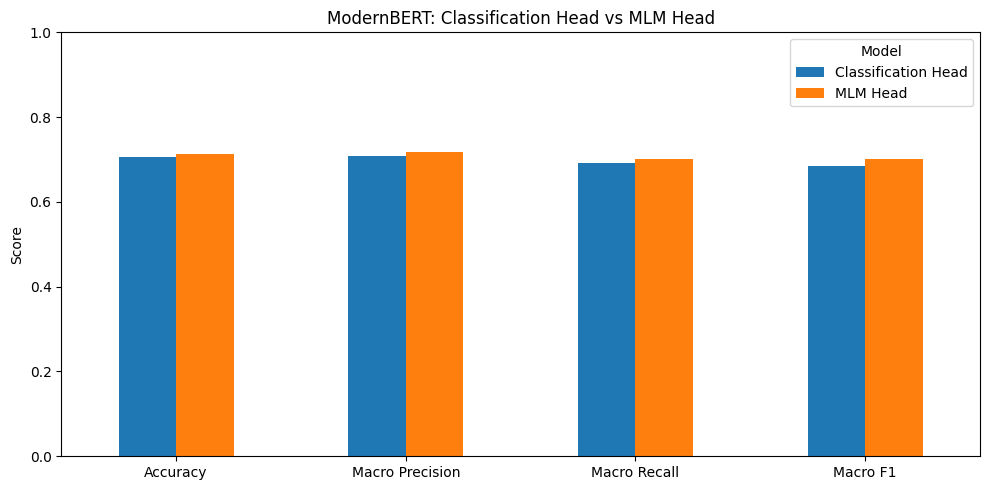

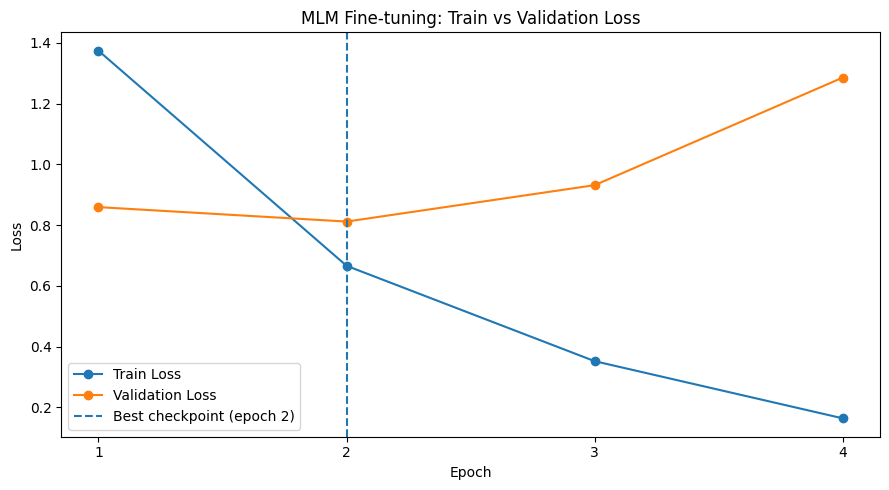

Graficele și rezultatele au fost salvate în Google Drive.


In [29]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Directorul pentru rezultate
results_dir = Path("/content/drive/MyDrive/NLP-Master/Lab02_Encoder_Finetuning/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Rezultatele obținute la evaluare
comparison = pd.DataFrame({
    "Model": ["Classification Head", "MLM Head"],
    "Accuracy": [0.7066, 0.7140],
    "Macro Precision": [0.7089, 0.7185],
    "Macro Recall": [0.6913, 0.7020],
    "Macro F1": [0.6844, 0.7011]
})

comparison.to_csv(results_dir / "model_comparison.csv", index=False)

# Graficul 1: comparația modelelor
comparison.set_index("Model").T.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("ModernBERT: Classification Head vs MLM Head")
plt.ylabel("Score")
plt.tight_layout()
plt.savefig(results_dir / "model_comparison.png", dpi=150)
plt.show()

# Graficul 2: evoluția loss-ului MLM
epochs = [1, 2, 3, 4]
train_loss = [1.3739, 0.6658, 0.3518, 0.1636]
val_loss = [0.8590, 0.8114, 0.9313, 1.2855]

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, marker="o", label="Train Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")
plt.axvline(x=2, linestyle="--", label="Best checkpoint (epoch 2)")

plt.title("MLM Fine-tuning: Train vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / "mlm_training_loss.png", dpi=150)
plt.show()

print("Graficele și rezultatele au fost salvate în Google Drive.")
